In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from scipy import stats
from scipy.stats import norm



In [32]:
df = pd.read_csv("dados/dados_SIM_Para_Analise.csv")
df.shape
df['DTOBITO'] = pd.to_datetime(df['DTOBITO'], errors='coerce')
df['CAUSABAS'] = 'infarto'


df_morte_capitais = pd.read_excel('dados/populacao_capitais_brasil_2026.xlsx')
df_morte_capitais.head()



df = df.loc[df['ANOOBITO'] <= 2024]


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15016 entries, 0 to 15015
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   CAUSABAS    15016 non-null  object        
 1   DTOBITO     15016 non-null  datetime64[ns]
 2   SEXO        15016 non-null  int64         
 3   IDADE       15016 non-null  int64         
 4   TIPOBITO    15016 non-null  int64         
 5   RACACOR     15016 non-null  float64       
 6   ESC2010     15016 non-null  float64       
 7   ESCFALAGR1  15016 non-null  float64       
 8   LOCOCOR     15016 non-null  int64         
 9   ASSISTMED   15016 non-null  float64       
 10  codUf       15016 non-null  int64         
 11  ANOOBITO    15016 non-null  int64         
 12  Capital     15016 non-null  object        
 13  Sigla UF    15016 non-null  object        
dtypes: datetime64[ns](1), float64(4), int64(6), object(3)
memory usage: 1.7+ MB


In [34]:
'CAUSABAS', 
'DTOBITO', 
'SEXO',
'IDADE',
'TIPOBITO',
'RACACOR',
'ESC2010',
'ESCFALAGR1',
'LOCOCOR',
'ASSISTMED',
'codUf',
'ANOOBITO',
'Capital',
'Sigla UF'

'Sigla UF'

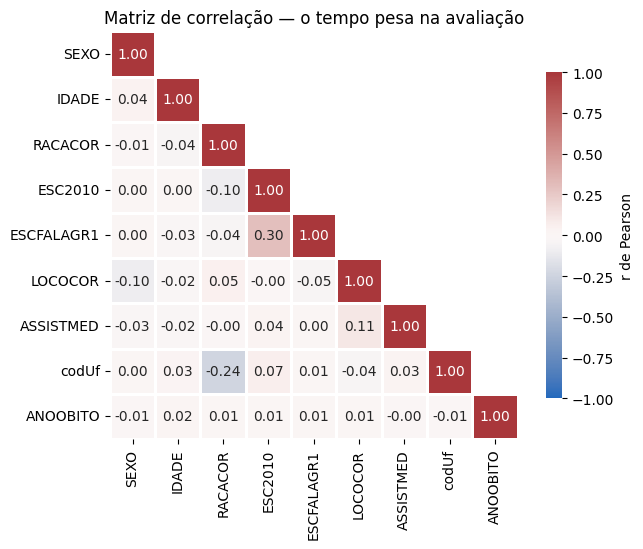

In [35]:
num = [
 
'SEXO',
'IDADE',
'RACACOR',
'ESC2010',
'ESCFALAGR1',
'LOCOCOR',
'ASSISTMED',
'codUf',
'ANOOBITO',

]
rotulos = [
 
'SEXO',
'IDADE',
'RACACOR',
'ESC2010',
'ESCFALAGR1',
'LOCOCOR',
'ASSISTMED',
'codUf',
'ANOOBITO',
]
corr = df[num].corr(method="pearson")
corr.index = corr.columns = rotulos
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7, 5.6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0,
            square=True, linewidths=1, linecolor="white",
            cbar_kws=dict(label="r de Pearson", shrink=0.8), annot_kws=dict(size=10), ax=ax)
ax.grid(False)
ax.set_title("Matriz de correlação — o tempo pesa na avaliação")
fig.tight_layout()
fig.savefig("fig/heatmap_correlacao.png", dpi=200, bbox_inches="tight")
plt.show()

In [36]:
df

,CAUSABAS,DTOBITO,SEXO,IDADE,TIPOBITO,RACACOR,ESC2010,ESCFALAGR1,LOCOCOR,ASSISTMED,codUf,ANOOBITO,Capital,Sigla UF
0,infarto,2022-02-23,1,43,2,1.0,3.0,12.0,3,2.0,24,2022,Natal,RN
1,infarto,2022-06-10,1,41,2,1.0,5.0,8.0,3,1.0,35,2022,São Paulo,SP
2,infarto,2022-02-06,1,41,2,1.0,1.0,10.0,4,2.0,43,2022,Porto Alegre,RS
3,infarto,2022-04-06,1,30,2,4.0,5.0,8.0,3,2.0,35,2022,São Paulo,SP
4,infarto,2022-01-20,1,26,2,1.0,3.0,12.0,1,1.0,52,2022,Goiânia,GO
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15011,infarto,2024-12-31,1,44,2,3.0,3.0,12.0,1,1.0,35,2024,São Paulo,SP
15012,infarto,2024-12-31,1,44,2,4.0,9.0,9.0,3,1.0,26,2024,Recife,PE
15013,infarto,2024-11-18,1,40,2,4.0,2.0,3.0,3,1.0,50,2024,Campo Grande,MS
15014,infarto,2024-11-09,2,38,2,1.0,5.0,8.0,5,2.0,50,2024,Campo Grande,MS


In [37]:
#df_natal['MESOBITO'] = df_natal['DTOBITO'].dt.month
#df_capitalx = df.loc[(df['IDADE'] <= 35)  & (df['Capital'] =='São Paulo')]


df_capital = df.groupby(['Capital'])['CAUSABAS'].count().sort_values(ascending=True).reset_index()

df_assistencia = df.groupby(['ASSISTMED'])['CAUSABAS'].count().reset_index()









### Total de mortes Por Ano:

<Figure size 2600x800 with 0 Axes>

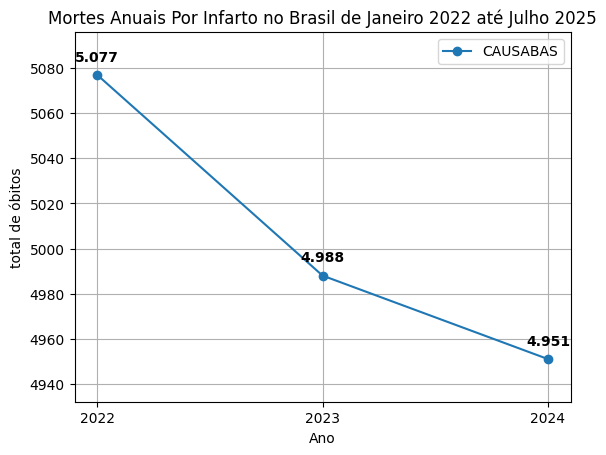

,index,CAUSABAS
0,mean,5005.333333
1,median,4988.000000
2,std,64.763673


In [51]:
#Grafico de Linha de total de mortes por Estados.
df_anoobito = df.groupby(['ANOOBITO'])['CAUSABAS'].count().reset_index()


plt.figure(figsize=(26, 8))

# 3. Criar o gráfico de barras
ax = df_anoobito.plot(x = "ANOOBITO", y="CAUSABAS", kind="line",marker="o", 
         title="Mortes Anuais Por Infarto no Brasil de Janeiro 2022 até Julho 2025")

for x, y in zip(df_anoobito["ANOOBITO"], df_anoobito["CAUSABAS"]):
  ax.annotate(
      f"{int(y):,}".replace(",", "."),
      (x, y),
      textcoords="offset points",
      xytext=(0, 10),
      ha="center",
      fontsize=10,
      fontweight="bold",
  )
  # 5. Ajustar margem superior para o número não cortar no topo
ax.margins(y=0.15)


# 6. Ajustar grade e exibir
plt.xticks(df_anoobito["ANOOBITO"].astype(int))
plt.xlabel("Ano")
plt.ylabel("total de óbitos")
plt.grid(True)
plt.show()

ano_causa = df.groupby("ANOOBITO")["CAUSABAS"].count().reset_index()

df_resultado = ano_causa['CAUSABAS'].agg(['mean', 'median', 'std']).T.reset_index()
df_resultado

### Mortes por Sexo Geral e por Ano: 

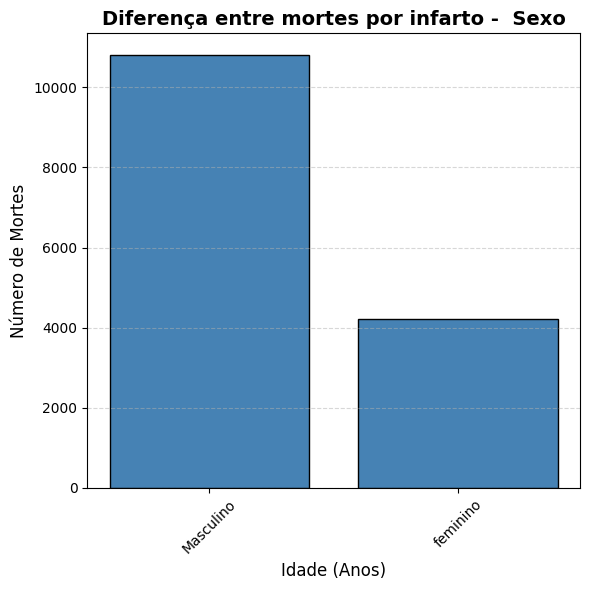

0    Masculino
1     feminino
Name: SEXO, dtype: object

In [39]:
df_agrupado = df.groupby(['SEXO'])['CAUSABAS'].count().reset_index()

plt.figure(figsize=(6, 6))
mapa_assistencia = {
    1.0: 'Masculino',
    2.0: 'feminino'
}
# 3. Criar o gráfico de barras
categoria = df_agrupado['SEXO'].map(mapa_assistencia)

categoria = categoria.astype(str)

barras = plt.bar(categoria, df_agrupado['CAUSABAS'], color='steelblue', edgecolor='black')

# 4. Adicionar títulos e rótulos nos eixos
plt.title('Diferença entre mortes por infarto -  Sexo', fontsize=14, fontweight='bold')
plt.xlabel('Idade (Anos)', fontsize=12)
plt.ylabel('Número de Mortes', fontsize=12)

# 5. Adicionar o valor exato no topo de cada barra
#for barra in barras:
#altura = barra.get_height()
#    plt.text(
 #       barra.get_x() + barra.get_width() / 2,
  #      altura + 10,  # Pequeno espaço acima da barra
   #     f'{int(altura)}',
    #    ha='center',
     #   va='bottom',
      #  fontsize=10
 #   )

# 6. Ajustar grade e exibir
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
fig.savefig("fig/grafico_barra_sexo.png", dpi=200, bbox_inches="tight")
plt.show()


df_agrupado['SEXO'].map(mapa_assistencia)

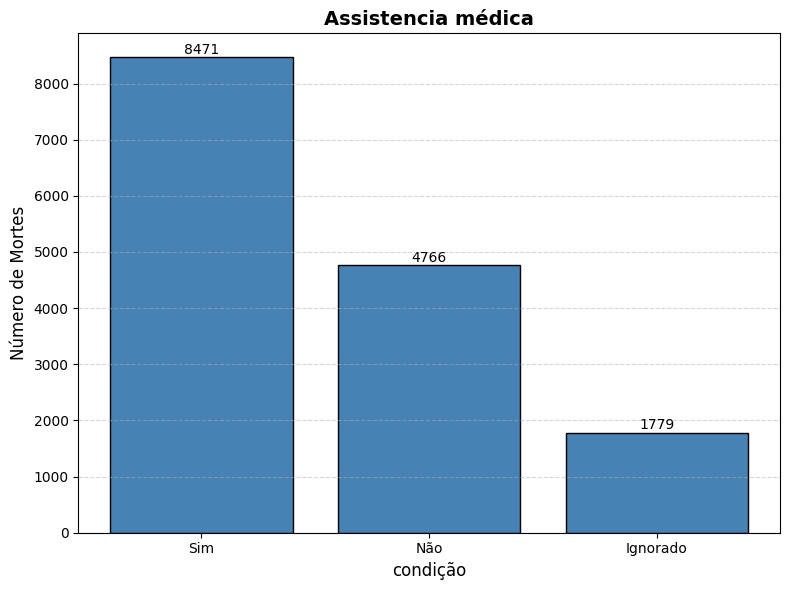

In [40]:


mapa_assistencia = {
    1: 'Sim',
    2: 'Não',
    9: 'Ignorado'
}

plt.figure(figsize=(8, 6))



# Cria a série com os nomes (caso a coluna seja float, ex: 1.0, o map também funciona)
categorias = df_assistencia['ASSISTMED'].map(mapa_assistencia)
# 3. Criar o gráfico de barras
barras = plt.bar(categorias, df_assistencia['CAUSABAS'], color='steelblue', edgecolor='black')
descricoes = ["Com assistência (1)", "Sem assistência (2)", "Ignorado (9)"]
# 4. Adicionar títulos e rótulos nos eixos
plt.title('Assistencia médica', fontsize=14, fontweight='bold')
plt.xlabel('condição', fontsize=12)
plt.ylabel('Número de Mortes', fontsize=12)

# 5. Adicionar o valor exato no topo de cada barra
for barra in barras:
    altura = barra.get_height()    
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 10,  # Pequeno espaço acima da barra
        f'{int(altura)}',
        ha='center',
        va='bottom',
        fontsize=10
    )

# 6. Ajustar grade e exibir
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
fig.savefig("fig/grafico_barra_assist.png", dpi=200, bbox_inches="tight")
plt.show()

<Figure size 600x600 with 0 Axes>

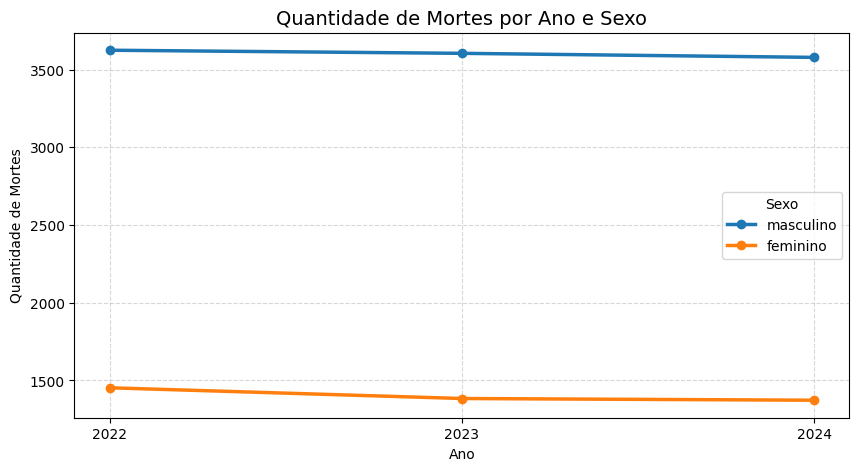

SEXO,1,2
ANOOBITO,,
2022,3624,1453
2023,3604,1384
2024,3578,1373


In [41]:
df_agrupado_ano = df.groupby(['ANOOBITO', 'SEXO']).size().unstack(fill_value=0)
plt.figure(figsize=(6, 6))
mapa_assistencia = {
    1.0: 'Masculino',
    2.0: 'feminino'
}
#categoria = df_agrupado_ano['SEXO'].map(mapa_assistencia)

# 2. Plota o gráfico
fig, ax = plt.subplots(figsize=(10, 5))

for sexo in df_agrupado_ano.columns:
    ax.plot(df_agrupado_ano.index, df_agrupado_ano[sexo], marker='o', linewidth=2.5, label=sexo)

ax.set_title('Quantidade de Mortes por Ano e Sexo', fontsize=14)
ax.set_xlabel('Ano')
ax.set_ylabel('Quantidade de Mortes')
ax.legend(title='Sexo', labels=['masculino','feminino'])
ax.set_xticks(df_agrupado_ano.index)
ax.grid(True, linestyle='--', alpha=0.5)

plt.show()


df_agrupado_ano.head()

### Mortes por Infarto por Capitais

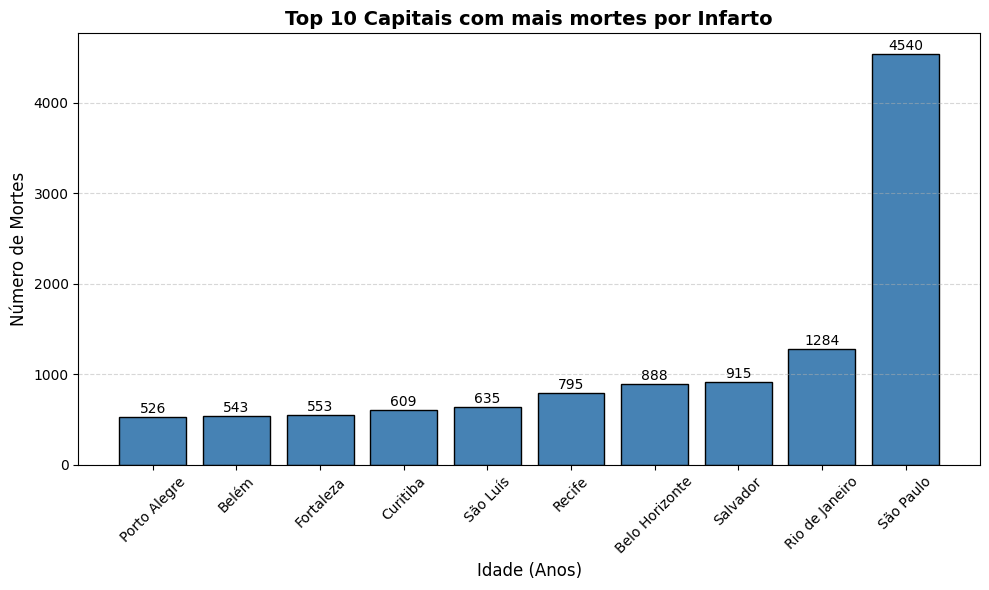

In [42]:
df_Capital = df.groupby(['ANOOBITO','Capital']).size().unstack(fill_value=0)

plt.figure(figsize=(10, 6))

# 3. Criar o gráfico de barras
barras = plt.bar(df_capital['Capital'].tail(10), df_capital['CAUSABAS'].tail(10), color='steelblue', edgecolor='black')

# 4. Adicionar títulos e rótulos nos eixos
plt.title('Top 10 Capitais com mais mortes por Infarto', fontsize=14, fontweight='bold')
plt.xlabel('Idade (Anos)', fontsize=12)
plt.ylabel('Número de Mortes', fontsize=12)

# 5. Adicionar o valor exato no topo de cada barra
for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura + 10,  # Pequeno espaço acima da barra
        f'{int(altura)}',
        ha='center',
        va='bottom',
        fontsize=10
    )

# 6. Ajustar grade e exibir
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
fig.savefig("fig/grafico_barra.png", dpi=200, bbox_inches="tight")
plt.show()



### Mortes por infartos nas Capitais por 100k Habitantes

In [43]:
df_capital_anual = df.groupby(['ANOOBITO','Capital'])['CAUSABAS'].count().reset_index()


df_m100k_habitantes = pd.merge(
    df_capital,
    df_morte_capitais,
    left_on="Capital",
    right_on="Capital",
    how='left'
)   

df_m100k_habitantes['mortes_por_100K_habitantes'] = ((df_m100k_habitantes['CAUSABAS'] / df_m100k_habitantes['População Estimada (2026)'])*100000).round(2)

 
df_m100k_habitantes= df_m100k_habitantes.sort_values(by=['mortes_por_100K_habitantes'],ascending=False)



df_m100k_habitantes

,Capital,CAUSABAS,Posição,UF,População Estimada (2026),mortes_por_100K_habitantes
8,Vitória,257,26.0,ES,343935,74.72
15,Florianópolis,388,21.0,SC,598370,64.84
21,São Luís,635,13.0,MA,1090229,58.24
22,Recife,795,9.0,PE,1588983,50.03
13,Natal,343,18.0,RN,783196,43.79
6,Palmas,135,27.0,TO,333154,40.52
14,João Pessoa,353,17.0,PB,906093,38.96
18,Belém,543,11.0,PA,1396157,38.89
26,São Paulo,4540,1.0,SP,11911337,38.11
17,Porto Alegre,526,12.0,RS,1388791,37.87


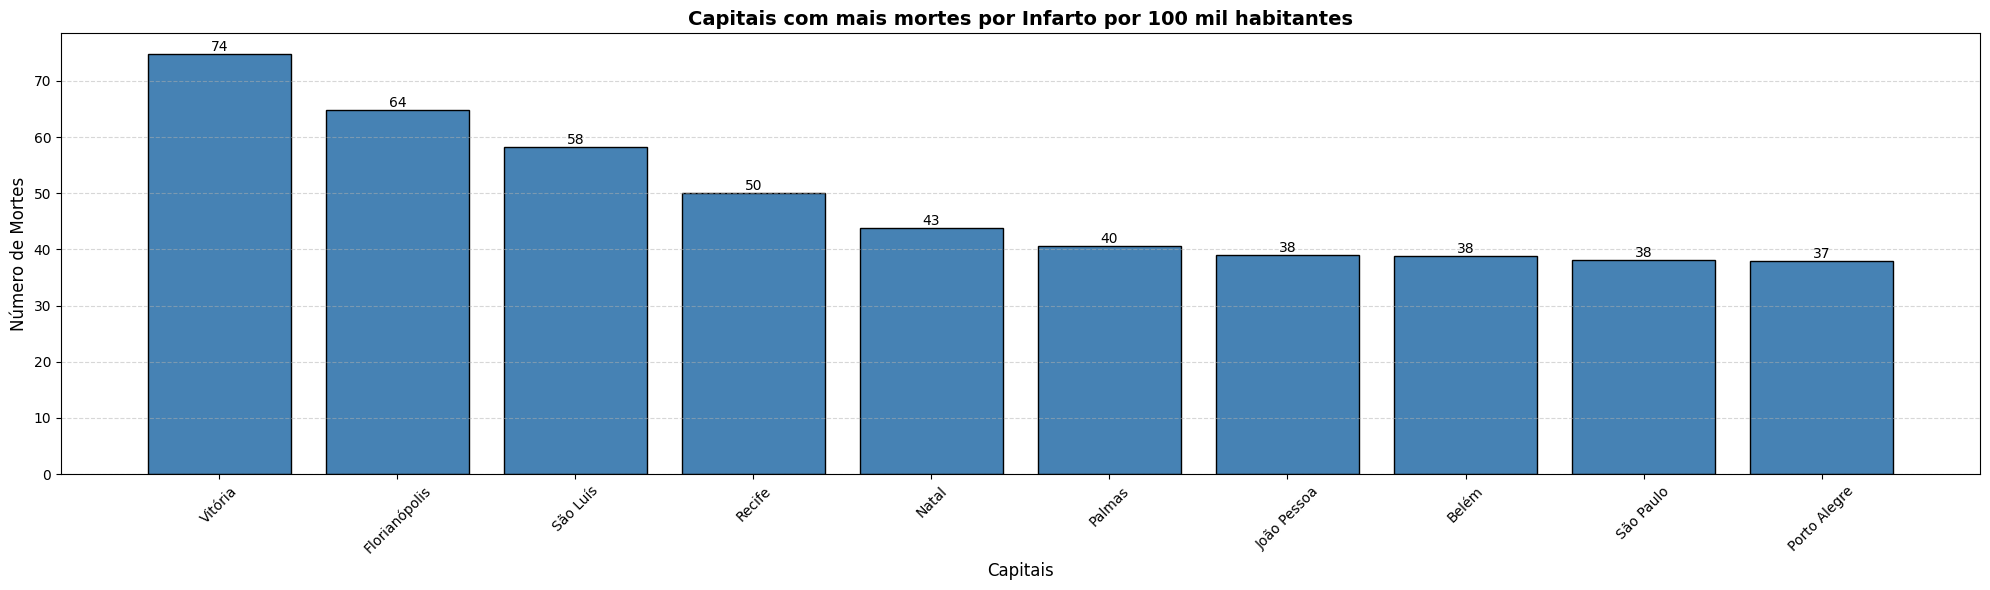

In [44]:
plt.figure(figsize=(20, 6))

# 3. Criar o gráfico de barras
barras = plt.bar(df_m100k_habitantes['Capital'].head(10), df_m100k_habitantes['mortes_por_100K_habitantes'].head(10), color='steelblue', edgecolor='black')

# 4. Adicionar títulos e rótulos nos eixos
plt.title('Capitais com mais mortes por Infarto por 100 mil habitantes', fontsize=14, fontweight='bold')
plt.xlabel('Capitais', fontsize=12)
plt.ylabel('Número de Mortes', fontsize=12)

# 5. Adicionar o valor exato no topo de cada barra
for barra in barras:
    altura = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        altura ,  # Pequeno espaço acima da barra
        f'{int(altura)}',
        ha='center',
        va='bottom',
        fontsize=10
    )

# 6. Ajustar grade e exibir
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
fig.savefig("fig/grafico_barra.png", dpi=200, bbox_inches="tight")
plt.show()

In [45]:
df_m100k_habitantes['mortes_por_100K_habitantes'].agg(['mean','median','std'])

mean      32.428148
median    34.200000
std       17.310306
Name: mortes_por_100K_habitantes, dtype: float64

In [54]:
Q1 = df_m100k_habitantes['mortes_por_100K_habitantes'].quantile(0.25)
Q3 = df_m100k_habitantes['mortes_por_100K_habitantes'].quantile(0.75)


IQR = Q3 - Q1

print(f"Q1 (25%): {Q1:.2f}")
print(f"Mediana (50%): {df_m100k_habitantes['mortes_por_100K_habitantes'].median():.2f}")
print(f"Q3 (75%): {Q3:.2f}")
print(f"IQR: {IQR:.2f}")

Q1 (25%): 18.90
Mediana (50%): 34.20
Q3 (75%): 38.92
IQR: 20.02


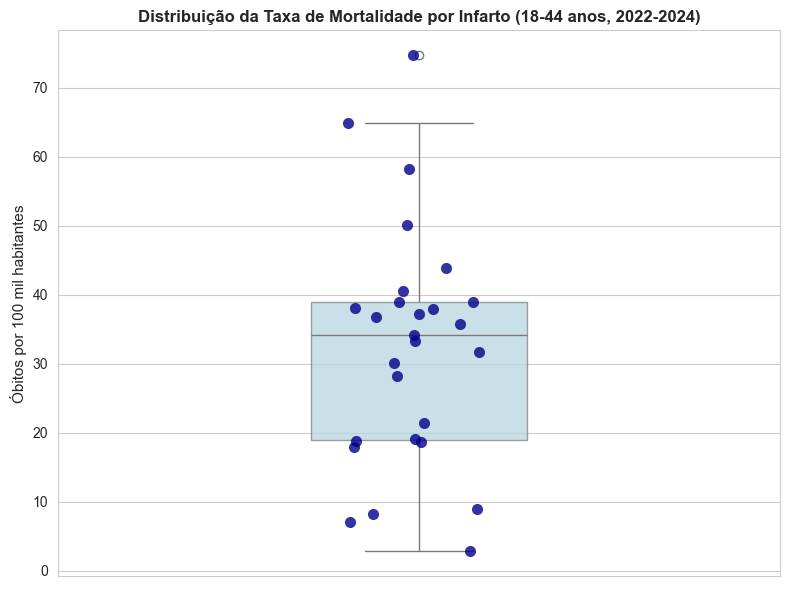

In [55]:
# Configura o estilo e o tamanho da imagem
plt.figure(figsize=(8, 6))
sns.set_style("whitegrid")

# 1. Cria o Boxplot (mostra Mediana, Q1, Q3 e limites)
sns.boxplot(
    y=df_m100k_habitantes['mortes_por_100K_habitantes'], 
    color='lightblue', 
    width=0.3, 
    boxprops=dict(alpha=0.7)
)

# 2. Adiciona os pontos de cada capital por cima (opcional, mas muito útil)
sns.stripplot(
    y=df_m100k_habitantes['mortes_por_100K_habitantes'], 
    color='darkblue', 
    size=8, 
    jitter=True, 
    alpha=0.8
)

# Títulos e rótulos
plt.title('Distribuição da Taxa de Mortalidade por Infarto (18-44 anos, 2022-2024)', fontsize=12, fontweight='bold')
plt.ylabel('Óbitos por 100 mil habitantes', fontsize=11)

plt.tight_layout()
plt.show()

In [59]:
df_m100k_habitantes_semFeV = df_m100k_habitantes ['mortes_por_100K_habitantes'].loc[
(df_m100k_habitantes['mortes_por_100K_habitantes'] <= 65) & (df_m100k_habitantes['mortes_por_100K_habitantes'] >= 20)]

df_m100k_habitantes_semFeV.agg(['mean','median','std'])

mean      38.868333
median    37.535000
std       10.356098
Name: mortes_por_100K_habitantes, dtype: float64